In [1]:
from metrics import calculate_celltype_separation
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LogisticRegression

import anndata as ad
import numpy as np
import pandas as pd



In [2]:
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/cosmx_nsclc_Lung5-Rep3_adata_annotated_med_with_admix_probs.h5ad')

In [3]:
sc_data_corrected = sc_data.copy()

In [4]:
# QC
raw_count_mask = sc_data.X.sum(axis=1) >= 10
min_genes = (sc_data.X > 0).sum(axis=1) >= 5
sc_data = sc_data[raw_count_mask&min_genes]
sc_data.X.shape

# genes fewer than ten cells
min_exp = (sc_data.X > 0).sum(axis=0) >=10
sc_data = sc_data[:, min_exp]

# log(x+1) transformation
sc_data.X = np.log1p(sc_data.X)

In [5]:
# QC
adm_mask = sc_data_corrected.layers['admix_probs'].toarray() > 0.75
sc_data_corrected.X[adm_mask] = 0
raw_count_mask = sc_data_corrected.X.sum(axis=1) >= 10
min_genes = (sc_data_corrected.X > 0).sum(axis=1) >= 5
sc_data_corrected = sc_data_corrected[raw_count_mask&min_genes]
sc_data_corrected.X.shape

# genes fewer than ten cells
min_exp = (sc_data_corrected.X > 0).sum(axis=0) >=10
sc_data_corrected = sc_data_corrected[:, min_exp]

# log(x+1) transformation
sc_data_corrected.X = np.log1p(sc_data_corrected.X)

In [6]:
from sklearn.decomposition import PCA

sc_data.obsm['X_pca'] = PCA(n_components=50).fit_transform(sc_data.X)
sc_data_corrected.obsm['X_pca'] = PCA(n_components=50).fit_transform(sc_data_corrected.X)

/tmp/ipykernel_3174698/397622412.py:3: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  sc_data.obsm['X_pca'] = PCA(n_components=50).fit_transform(sc_data.X)
/tmp/ipykernel_3174698/397622412.py:4: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  sc_data_corrected.obsm['X_pca'] = PCA(n_components=50).fit_transform(sc_data_corrected.X)


In [7]:
from umap import UMAP

sc_data.obsm['umap'] = UMAP().fit_transform(sc_data.obsm['X_pca'])
sc_data_corrected.obsm['umap'] = UMAP().fit_transform(sc_data_corrected.obsm['X_pca'])

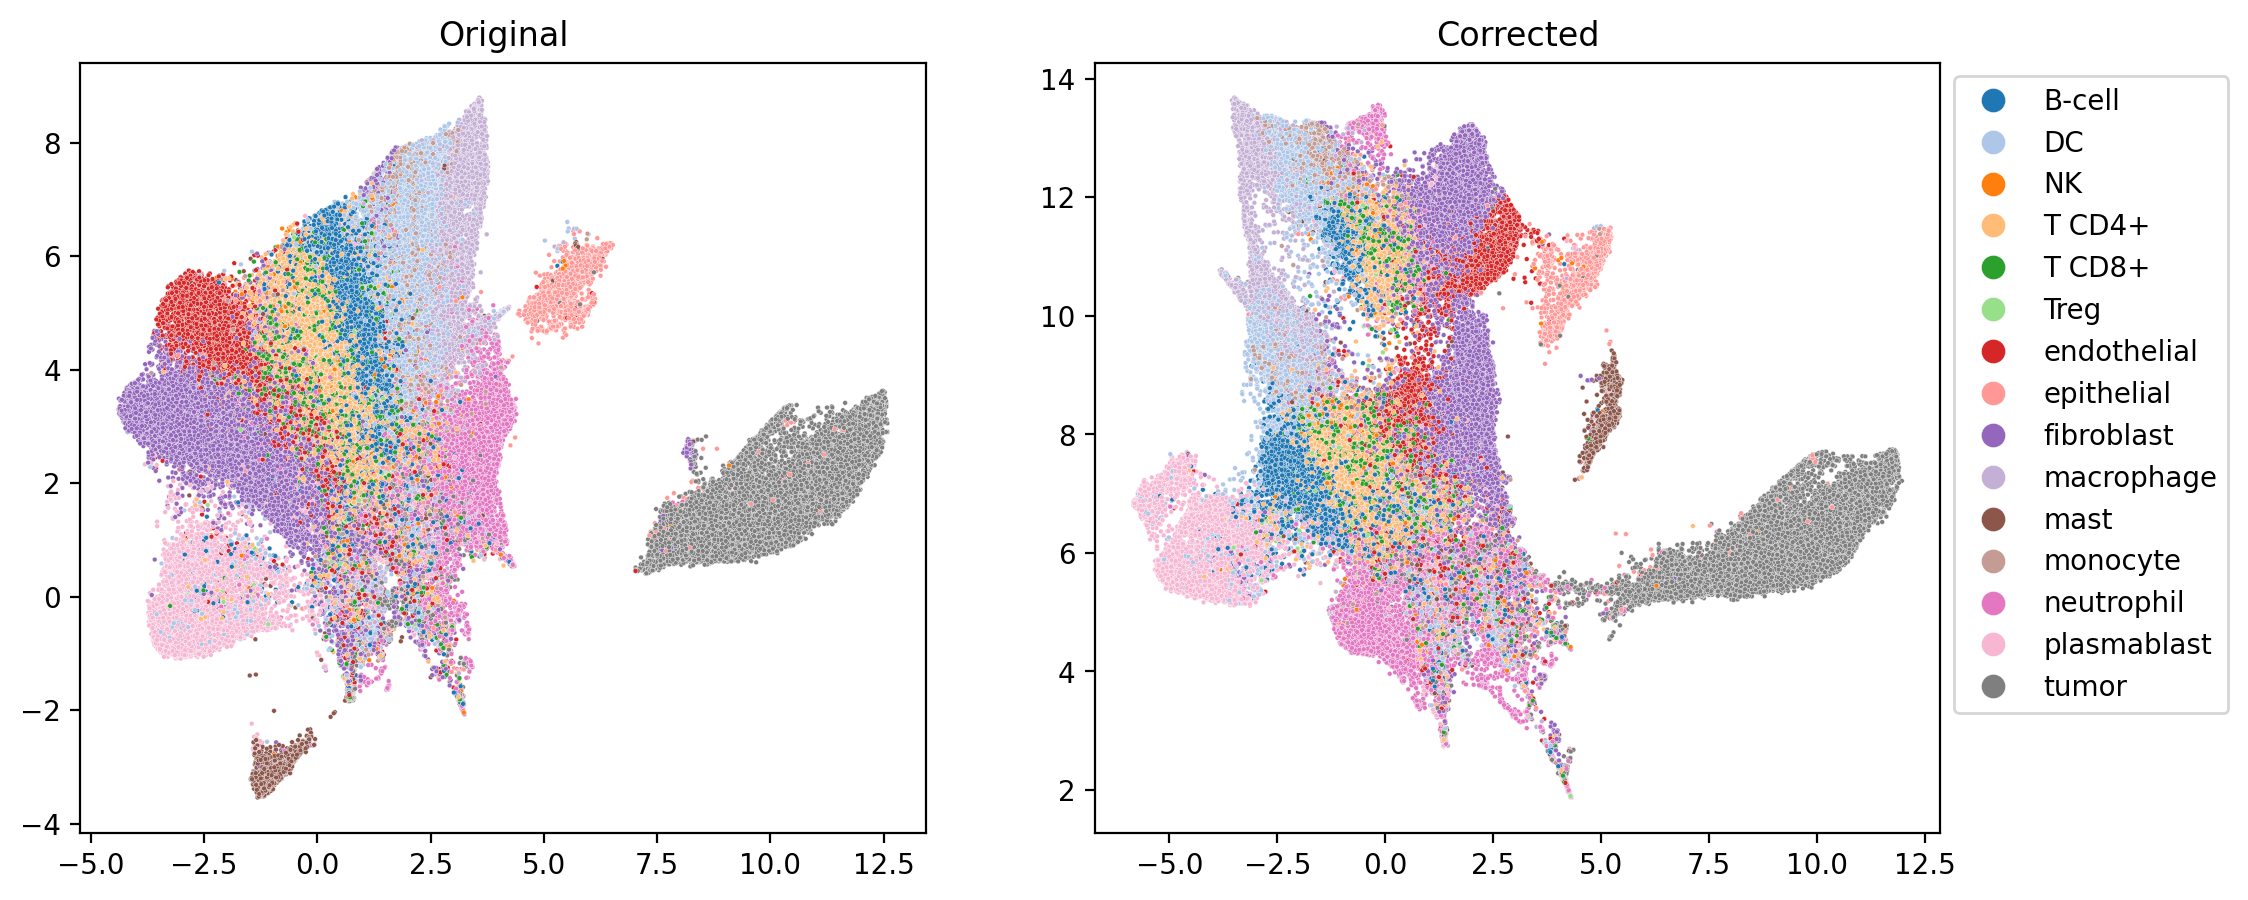

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

fig,axes = plt.subplots(ncols=2,figsize=(12,5),dpi=200)
ax= sns.scatterplot(x=sc_data.obsm['umap'][:,0],y=sc_data.obsm['umap'][:,1],hue=sc_data.obs['cell_type'],s=3,ax=axes[0],legend=False,palette='tab20')
ax.set_title('Original')
ax = sns.scatterplot(x=sc_data_corrected.obsm['umap'][:,0],y=sc_data_corrected.obsm['umap'][:,1],hue=sc_data_corrected.obs['cell_type'],s=3,ax=axes[1],palette='tab20')
ax.set_title("Corrected")
ax.legend(loc='upper left', bbox_to_anchor=(1, 1),markerscale=5)

In [9]:
for score_func in [calinski_harabasz_score,davies_bouldin_score]:
    print(score_func(sc_data.obsm["X_pca"],sc_data.obs['cell_type']),score_func(sc_data_corrected.obsm["X_pca"],sc_data_corrected.obs['cell_type']))

3333.070236999658 3263.914581529948
4.50212758029999 4.7652166971532415


In [ ]:
st_data = 

In [ ]:
reg = LogisticRegression()

reg = 